# Civet Behavior — YOLO Room + ResNet18 Behavior (intermediate system)
Uses saved results from `resnet18_train.ipynb` (ResNet behavior per camera per second)
and `yolo_train.ipynb` (YOLO civet detection and room per second).
Room comes from YOLO (last room seen when no camera detects the civet);
behavior comes from the ResNet-only pipeline.

**Status:** intermediate step, kept for comparison. The final system is
`resnet18_crop_train.ipynb` (ResNet18 trained on YOLO crops), which reads
`c9_yolo_timeline.csv` from this notebook as the "previous system".

**Note:** the baseline ResNet used here had 160 training images inside the test hour,
so its test scores may be optimistic.

### Variants tried before this version (same test hour, 5-s smoothing)
| Variant | Behavior acc | A/I (a) | A/I (b) | Room acc |
|---|---|---|---|---|
| ResNet only | 0.534 | 0.728 | 0.580 | 0.626 |
| YOLO room + ResNet of that camera | 0.494 | 0.676 | 0.606 | 0.814 |
| + no Unknown when YOLO sees the civet but ResNet says Not_visible | 0.489 | 0.674 | 0.604 | 0.814 |
| + YOLO 1-body-length move rule + last room | 0.441 | 0.596 | 0.469 | 0.886 |
| **Kept: YOLO room + ResNet-only behavior** | **0.534** | **0.728** | **0.580** | **0.886** |

A/I (a) = trained behaviors only; A/I (b) = ground-truth Grooming/Urination counted as Active.

Using YOLO to change the behavior step made results worse in every variant:
the camera that YOLO picks often sees a small / far civet, and the 1-body-length rule
was too strict (box includes the tail), so walking became Inactive.
Error analysis of the first variant: when YOLO detects the civet, accuracy 0.653 vs 0.698
(ResNet only); in the 64 s when no camera detects it, ground truth was mostly
Locomotion (43 s) and Feeding (11 s), i.e. YOLO detection gaps, not the sleeping box.


## Cell 1: Setup — mount Drive, imports, paths

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pathlib import Path
from collections import Counter

BASE = Path('/content/drive/MyDrive/civet2')
RESULTS = BASE / 'results'
MODELS = BASE / 'models'
CAMERAS = ['A01', 'A02', 'A03', 'A04']

Mounted at /content/drive


## Cell 2: YOLO room + ResNet behavior per second

In [ ]:
# ===== Cell 2: YOLO room + ResNet behavior per second =====
# Input : c9_timeline.csv (ResNet-only system, ground truth), y7_room.csv, y7_detections.csv
# Output: c9_yolo_timeline.csv
# Room = YOLO room per second; when no camera detects the civet -> last room seen by YOLO
#   (A02 before the first detection).
# Behavior = ResNet-only system (resnet18_train.ipynb, Step 9), unchanged.

def hms(s):
    h, m, x = map(int, s.split(':'))
    return h * 3600 + m * 60 + x

def to_sec(df):
    if 'sec' in df.columns:
        return df['sec'].astype(int)
    for c in ['time', 'timestamp', 'clock']:
        if c in df.columns:
            return df[c].astype(str).str[:8].map(hms)
    raise KeyError(f'No sec/time column in {list(df.columns)}')

def cam_id(x):
    """'A03', 'Camera3', 3 -> 'A03'; 'In_box' stays 'In_box'."""
    d = re.findall(r'\d+', str(x))
    return f'A{int(d[-1]):02d}' if d else str(x)

# ---------- YOLO detection share per camera ----------
det = pd.read_csv(RESULTS / 'y7_detections.csv')
det['camera'] = det['camera'].map(cam_id)
print('Share of seconds with a YOLO detection:',
      det.assign(hit=det['n_det'] > 0).groupby('camera')['hit'].mean().round(2).to_dict())

# ---------- Combine ----------
yroom = pd.read_csv(RESULTS / 'y7_room.csv')
yroom = pd.DataFrame({'sec': to_sec(yroom),
                      'room_yolo': yroom['pred_smooth'].map(cam_id)}).drop_duplicates('sec')
keep = ['sec', 'time', 'gt', 'gt_room', 'room_rule', 'beh_rule']
tl = pd.read_csv(RESULTS / 'c9_timeline.csv')[keep].merge(yroom, on='sec', how='left')
tl = tl.sort_values('sec').reset_index(drop=True)
tl['yolo_seen'] = tl['room_yolo'].isin(CAMERAS)
print('Seconds without a YOLO detection:', int((~tl['yolo_seen']).sum()))

# behavior: ResNet-only system
tl['beh_yolo'] = tl['beh_rule']
# room: no detection -> last room seen by YOLO (A02 before the first detection)
tl['room_yolo'] = tl['room_yolo'].where(tl['yolo_seen']).ffill().fillna('A02')

tl.to_csv(RESULTS / 'c9_yolo_timeline.csv', index=False)
print('Saved:', RESULTS / 'c9_yolo_timeline.csv', f'({len(tl)} seconds)')
display(pd.crosstab(tl['gt_room'], tl['room_yolo']))


Share of seconds with a YOLO detection: {'A01': 0.12, 'A02': 0.34, 'A03': 0.27, 'A04': 0.33}
Seconds without a YOLO detection: 127
Saved: /content/drive/MyDrive/civet2/results/c9_yolo_timeline.csv (1463 seconds)


room_yolo,A01,A02,A03,A04
gt_room,,,,
-,0,20,0,19
A01,113,11,0,0
A02,44,351,7,0
A03,0,65,278,16
A04,0,0,19,520


## Cell 3: Output and comparison (ResNet only vs ResNet + YOLO room)

Comparison (5-s smoothing for both systems):


,system,behavior_acc,active_inactive_a,active_inactive_b_unknown_as_active,room_acc,feeding_events,drinking_events
0,ResNet only,0.534,0.728,0.58,0.626,5,1
1,ResNet + YOLO,0.534,0.728,0.58,0.886,5,1
2,Ground truth,NaN,NaN,NaN,NaN,4,2


,system_s,ground_truth_s,system_%,ground_truth_%
Inactive,720,296,49.2,20.2
Locomotion,561,631,38.3,43.1
Feeding,135,119,9.2,8.1
Drinking,5,66,0.3,4.5
Unknown,42,304,2.9,20.8
Unclear,0,47,0.0,3.2


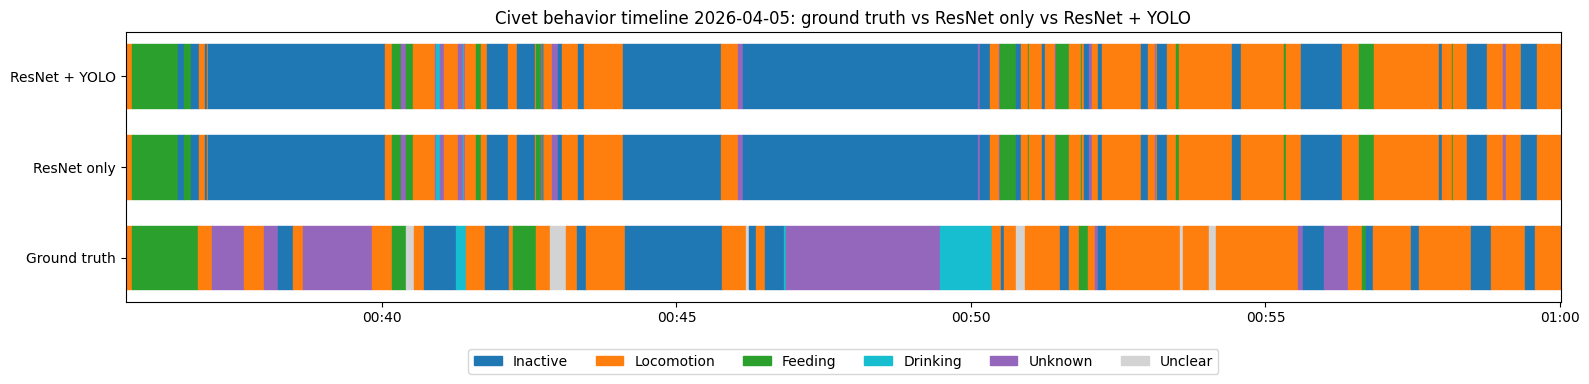

Saved: /content/drive/MyDrive/civet2/results/c10_yolo_observation_sheet.xlsx


In [ ]:
# ===== Cell 3: Output and comparison (ResNet only vs ResNet + YOLO room) =====
# Input : c9_yolo_timeline.csv
# Output: c10_yolo_comparison.csv, c10_yolo_timeline.png, c10_yolo_observation_sheet.xlsx
DATE = '2026-04-05'
SMOOTH_S = 5
MERGE_GAP_S = 60
MIN_EVENT_S = 5
ROOM = {'A01': 'A01 empty room', 'A02': 'A02 sleeping box',
        'A03': 'A03 food tray', 'A04': 'A04 water tray'}

def fmt(sec):
    return f'{sec // 3600:02d}:{sec % 3600 // 60:02d}:{sec % 60:02d}'

def smooth(values, k=SMOOTH_S):
    v, h = list(values), k // 2
    return [Counter(v[max(0, i - h): i + h + 1]).most_common(1)[0][0]
            for i in range(len(v))]

def split_fd(beh, room):
    if beh != 'Feeding_Drinking':
        return beh
    return 'Drinking' if room == 'A04' else 'Feeding'

def status(beh):
    if beh == 'Inactive':
        return 'Inactive'
    if beh in ('Locomotion', 'Feeding', 'Drinking'):
        return 'Active'
    return beh

def events(secs, labels, target):
    on = [s for s, l in zip(secs, labels) if l == target]
    runs = []
    for s in on:
        if runs and s - runs[-1][1] <= 1:
            runs[-1][1] = s
        else:
            runs.append([s, s])
    merged = []
    for r in runs:
        if merged and r[0] - merged[-1][1] - 1 < MERGE_GAP_S:
            merged[-1][1] = r[1]
        else:
            merged.append(r)
    return [(a, b) for a, b in merged if b - a + 1 >= MIN_EVENT_S]

tl = pd.read_csv(RESULTS / 'c9_yolo_timeline.csv').sort_values('sec').reset_index(drop=True)
tl['gt_beh'] = [split_fd(b, r) if isinstance(b, str) else 'Unclear'
                for b, r in zip(tl['gt'], tl['gt_room'])]
tl['gt_status'] = tl['gt_beh'].map(status)
tl['gt_status_eth'] = tl['gt_status'].replace({'Unknown': 'Active'})
ok = tl['gt_beh'] != 'Unclear'
vis = ok & tl['gt_status'].isin(['Active', 'Inactive'])
vis_eth = ok & tl['gt_status_eth'].isin(['Active', 'Inactive'])

# ---------- Both systems with the same smoothing and metrics ----------
SYSTEMS = {'ResNet only': ('room_rule', 'beh_rule'),
           'ResNet + YOLO': ('room_yolo', 'beh_yolo')}
out, rows = {}, []
for name, (rc, bc) in SYSTEMS.items():
    room = smooth(tl[rc])
    beh = [split_fd(b, r) for b, r in zip(smooth(tl[bc]), room)]
    d = pd.DataFrame({'sec': tl['sec'], 'room': room, 'beh': beh})
    d['status'] = d['beh'].map(status)
    out[name] = d
    rows.append({
        'system': name,
        'behavior_acc': round((d.loc[ok, 'beh'] == tl.loc[ok, 'gt_beh']).mean(), 3),
        'active_inactive_a': round((d.loc[vis, 'status'] == tl.loc[vis, 'gt_status']).mean(), 3),
        'active_inactive_b_unknown_as_active':
            round((d.loc[vis_eth, 'status'] == tl.loc[vis_eth, 'gt_status_eth']).mean(), 3),
        'room_acc': round((d.loc[ok, 'room'] == tl.loc[ok, 'gt_room']).mean(), 3),
        'feeding_events': len(events(d['sec'], d['beh'], 'Feeding')),
        'drinking_events': len(events(d['sec'], d['beh'], 'Drinking'))})
rows.append({'system': 'Ground truth',
             'feeding_events': len(events(tl['sec'], tl['gt_beh'], 'Feeding')),
             'drinking_events': len(events(tl['sec'], tl['gt_beh'], 'Drinking'))})
comp = pd.DataFrame(rows)
comp.to_csv(RESULTS / 'c10_yolo_comparison.csv', index=False)
print('Comparison (5-s smoothing for both systems):')
display(comp)

# ---------- Outputs for ResNet + YOLO ----------
d = out['ResNet + YOLO']
ev_rows = []
for who, labels in [('System', d['beh']), ('Ground truth', tl['gt_beh'])]:
    for target in ['Feeding', 'Drinking']:
        for a, b in events(tl['sec'], labels, target):
            ev_rows.append({'source': who, 'behavior': target, 'start': fmt(a),
                            'end': fmt(b), 'duration_s': b - a + 1, 'start_sec': a})
ev = pd.DataFrame(ev_rows, columns=['source', 'behavior', 'start', 'end',
                                    'duration_s', 'start_sec'])

d['minute'] = d['sec'] // 60 * 60
d['gt_beh'] = tl['gt_beh']
minute_rows = []
for m, g in d.groupby('minute'):
    starts = ev[(ev['source'] == 'System') & (ev['start_sec'] // 60 * 60 == m)]
    minute_rows.append({
        'date': DATE, 'time': fmt(m)[:5],
        'room': ROOM[g['room'].mode()[0]],
        'behavior': g['beh'].mode()[0],
        'status': g['status'].mode()[0],
        'active_s': int((g['status'] == 'Active').sum()),
        'inactive_s': int((g['status'] == 'Inactive').sum()),
        'feeding_events': int((starts['behavior'] == 'Feeding').sum()),
        'drinking_events': int((starts['behavior'] == 'Drinking').sum()),
        'gt_behavior': g['gt_beh'].mode()[0]})
minute_tab = pd.DataFrame(minute_rows)

n = len(d)
r = comp[comp['system'] == 'ResNet + YOLO'].iloc[0]
g_t = comp[comp['system'] == 'Ground truth'].iloc[0]
hourly = pd.DataFrame([{
    'date': DATE, 'window': f"{fmt(d['sec'].iloc[0])} - {fmt(d['sec'].iloc[-1])}",
    'minutes': round(n / 60, 1),
    'active_%': round((d['status'] == 'Active').mean() * 100, 1),
    'inactive_%': round((d['status'] == 'Inactive').mean() * 100, 1),
    'gt_active_%': round((tl['gt_status'] == 'Active').mean() * 100, 1),
    'gt_active_incl_unknown_%': round((tl['gt_status_eth'] == 'Active').mean() * 100, 1),
    'gt_inactive_%': round((tl['gt_status'] == 'Inactive').mean() * 100, 1),
    'feeding_events': int(r['feeding_events']), 'gt_feeding_events': int(g_t['feeding_events']),
    'drinking_events': int(r['drinking_events']), 'gt_drinking_events': int(g_t['drinking_events']),
    'behavior_accuracy': r['behavior_acc'],
    'active_inactive_accuracy_a': r['active_inactive_a'],
    'active_inactive_accuracy_b_unknown_as_active': r['active_inactive_b_unknown_as_active'],
    'room_accuracy': r['room_acc']}])

BEH = ['Inactive', 'Locomotion', 'Feeding', 'Drinking', 'Unknown', 'Unclear']
beh_sum = pd.DataFrame({
    'system_s': d['beh'].value_counts().reindex(BEH, fill_value=0),
    'ground_truth_s': tl['gt_beh'].value_counts().reindex(BEH, fill_value=0)})
beh_sum['system_%'] = (beh_sum['system_s'] / n * 100).round(1)
beh_sum['ground_truth_%'] = (beh_sum['ground_truth_s'] / n * 100).round(1)
display(beh_sum)

# ---------- Figure: ground truth vs ResNet only vs ResNet + YOLO ----------
COL = {'Inactive': 'tab:blue', 'Locomotion': 'tab:orange', 'Feeding': 'tab:green',
       'Drinking': 'tab:cyan', 'Unknown': 'tab:purple', 'Unclear': 'lightgray'}

def bars(labels):
    v, out_b, start = list(labels), [], 0
    for i in range(1, len(v) + 1):
        if i == len(v) or v[i] != v[start]:
            out_b.append((tl['sec'].iloc[start], i - start, v[start]))
            start = i
    return out_b

lines = [('Ground truth', tl['gt_beh']), ('ResNet only', out['ResNet only']['beh']),
         ('ResNet + YOLO', d['beh'])]
fig, ax = plt.subplots(figsize=(16, 4))
for y, (name, labels) in enumerate(lines):
    for x0, w, lab in bars(labels):
        ax.broken_barh([(x0, w)], (y - 0.35, 0.7), color=COL.get(lab, 'black'))
ax.set_yticks(range(len(lines)), [l[0] for l in lines])
t0, t1 = tl['sec'].iloc[0], tl['sec'].iloc[-1]
ticks = list(range(t0 // 300 * 300 + 300, t1, 300))
ax.set_xticks(ticks, [fmt(t)[:5] for t in ticks])
ax.set_xlim(t0, t1)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COL.values()]
ax.legend(handles, COL.keys(), ncol=6, loc='upper center', bbox_to_anchor=(0.5, -0.15))
ax.set_title(f'Civet behavior timeline {DATE}: ground truth vs ResNet only vs ResNet + YOLO')
plt.tight_layout()
plt.savefig(RESULTS / 'c10_yolo_timeline.png', dpi=120)
plt.show()

# ---------- Excel ----------
xlsx = RESULTS / 'c10_yolo_observation_sheet.xlsx'
with pd.ExcelWriter(xlsx) as w:
    minute_tab.to_excel(w, sheet_name='Timeline', index=False)
    hourly.to_excel(w, sheet_name='Hourly summary', index=False)
    beh_sum.to_excel(w, sheet_name='Behavior summary')
    ev.drop(columns='start_sec').to_excel(w, sheet_name='Events', index=False)
    comp.to_excel(w, sheet_name='Comparison', index=False)
print('Saved:', xlsx)